# Esquema Estrella: Segmentaciones Dentales

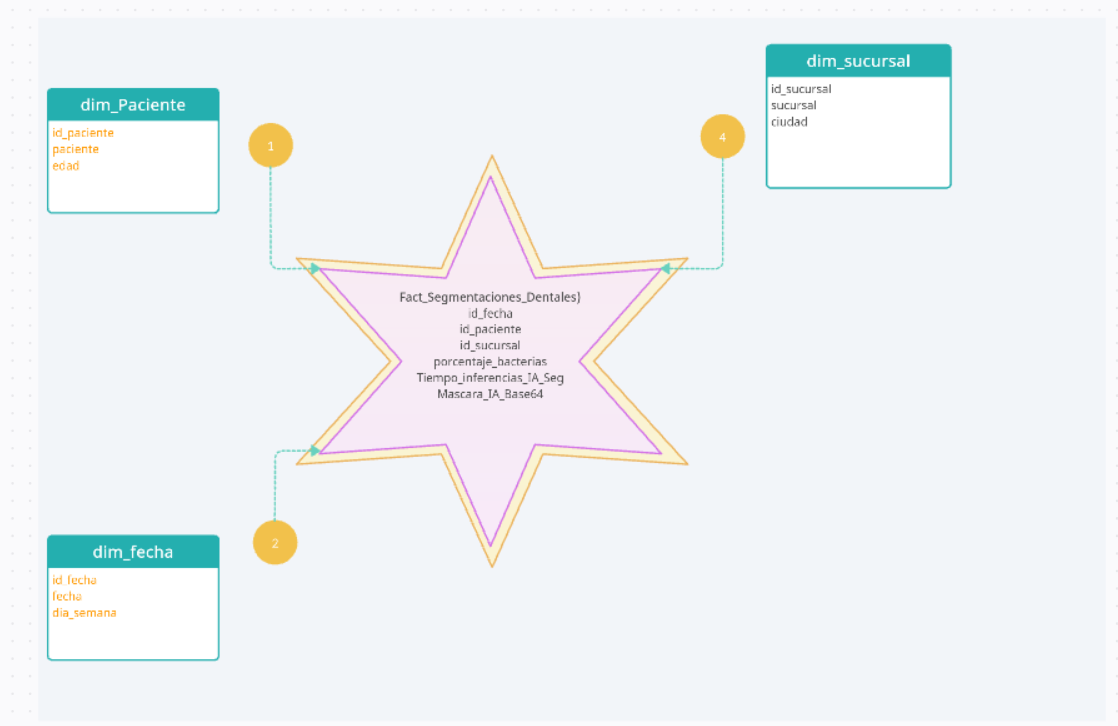

## 1. Tabla de Hechos: `Fact_Segmentaciones_Dentales`

**Llaves foráneas:** `id_fecha`, `id_paciente`, `id_sucursal`

**Métricas numéricas:**
- `porcentaje_bacterias`
- `Tiempo_inferencias_IA_Seg`

`Mascara_IA_Base64` **no** va aquí (ver pregunta 3).

## 2. Tablas de Dimensión

| Dimensión | Atributos |
|---|---|
| `dim_Paciente` | `id_paciente`, `paciente`, `edad` |
| `dim_fecha` | `id_fecha`, `fecha`, `dia_semana` |
| `dim_sucursal` | `id_sucursal`, `sucursal`, `ciudad` |

Con estas tablas el director puede ver el porcentaje de bacterias y el tiempo de la IA por paciente/edad, por día y por sucursal/ciudad.

## 3. Pregunta ETL: la máscara en Base64 (2 MB por fila)

**¿Por qué es un error cargarla en la Tabla de Hechos?**
- No es una métrica: no se puede sumar ni promediar.
- Cada fila pasaría de unos bytes a ~2 MB. Con miles de estudios al día la tabla crece a GB/TB muy rápido.
- Todas las consultas (`SUM`, `AVG`) se vuelven lentas porque tienen que leer esos 2 MB por fila aunque no los usen.

**¿Cómo lo resuelvo?**
En el Transform, decodifico el Base64, guardo la imagen como archivo (ej. en S3 o una carpeta) y en el warehouse solo guardo la **ruta** del archivo. El string Base64 se elimina antes del Load.

In [1]:
import base64, os

# Simulamos una fila que viene de la app web con la mascara en Base64
fila = {"id_fecha": 20260930, "id_paciente": 1, "id_sucursal": 1,
        "porcentaje_bacterias": 15.0, "tiempo_inferencias_ia_seg": 1.7,
        "mascara_ia_base64": base64.b64encode(os.urandom(1_500_000)).decode()}

print("Tamaño del Base64:", round(len(fila["mascara_ia_base64"]) / 1e6, 2), "MB")

# Transform: guardar la imagen como archivo y quedarnos solo con la ruta
os.makedirs("mascaras", exist_ok=True)
ruta = "mascaras/segmentacion_1.png"
with open(ruta, "wb") as f:
    f.write(base64.b64decode(fila.pop("mascara_ia_base64")))  # pop = se quita de la fila

print("Imagen guardada en:", ruta)

# Load: a la tabla de hechos solo van llaves y metricas
print("Fila que se carga:", fila)

Tamaño del Base64: 2.0 MB
Imagen guardada en: mascaras/segmentacion_1.png
Fila que se carga: {'id_fecha': 20260930, 'id_paciente': 1, 'id_sucursal': 1, 'porcentaje_bacterias': 15.0, 'tiempo_inferencias_ia_seg': 1.7}
